# MAR-HMM Example: two-channel MEG data

For this example, we will use MEG data from subjects performing a simple motor task. The data consist of 10 minute sessions of subjects who were asked to rest and tap with their left finger once every roughly 30 seconds (but without counting the time in between taps).

Each subject session data is stored as a 2D matrix with the shape of (No. of timepoints, No. of channels). Here there are only two channels from the motor cortex.

In [1]:
import sys, site

bad_path = r"C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages"
sys.path = [p for p in sys.path if bad_path.lower() not in p.lower()]

print("Python:", sys.executable)
print("User site:", site.getusersitepackages())
print("Bad path still present?", any(bad_path.lower() in p.lower() for p in sys.path))

import h5py
print("h5py:", h5py.__file__)

Python: c:\Users\pipo_\miniconda3\envs\glhmm\python.exe
User site: C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages
Bad path still present? False
h5py: c:\Users\pipo_\miniconda3\envs\glhmm\lib\site-packages\h5py\__init__.py


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from glhmm import glhmm, preproc, utils, graphics, spectral, io, statistics, auxiliary
import pickle
import sys

In [3]:
# Loading the data in the notebook

with open("./MEG_data/data_MEG_MAR.pkl", "rb") as f:
    data_meg_mar = pickle.load(f)

# Display data information
print(f"Number of subjects in data_meg: {len(data_meg_mar)}")

Number of subjects in data_meg: 4


C:\Users\pipo_\AppData\Local\Temp\ipykernel_22096\1621453269.py:4: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  data_meg_mar = pickle.load(f)


In [4]:
data_meg_mar[0].shape

(300000, 2)

In [5]:
# concatenate subject data
X_concat = []
for j in range(len(data_meg_mar)):
    X_concat.extend(data_meg_mar[j])

X_concat = np.array(X_concat)

# Get the start and end indices for each session
idx_data = statistics.get_indices_from_list(data_meg_mar)
idx_data

array([[     0, 300000],
       [300000, 540000],
       [540000, 762000],
       [762000, 996000]])

In [6]:
X_concat.shape

(996000, 2)

In [7]:
# Preprocess data
X_preproc = preproc.preprocess_data(X_concat, idx_data)[0]

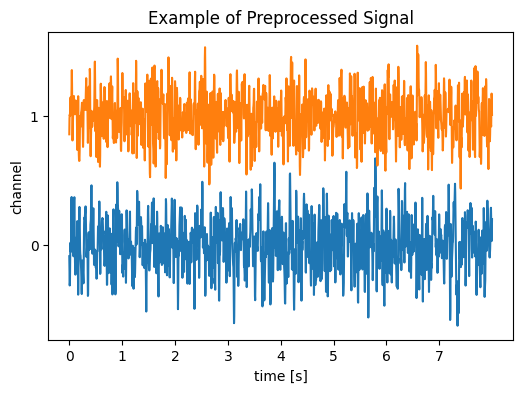

In [8]:
# visualize some data
# decide on a plotting range of the signal
plot_range = np.arange(200000,202000)

Fs = 250 # sampling frequency of the signal
n_regions = X_preproc.shape[1]

# plot each parcel separately
fig = plt.figure(figsize=(6,4))
for i in range(n_regions):
    plt.plot(X_preproc[plot_range,i]+i*5)

plt.xticks(np.arange(0,len(plot_range),Fs),np.arange(int(len(plot_range)/Fs)))
plt.xlabel('time [s]')
plt.yticks(np.arange(0,n_regions*5,5),np.arange(n_regions))
plt.ylabel('channel')
plt.title('Example of Preprocessed Signal')
plt.show()

**Initialise and train a MAR-HMM**

In the case of the MAR-HMM, this is done with two steps: we will first construct the data to regress, and the data to predict, then we will run a decoding (i.e. Gaussian Linear) HMM on the embedded data.

For the first step, we will use the build_data_maroption in the preprocessing module. This will create an embedded version of the data X and Y, so that in the GLHMM X will be used to predict Y.

To create the X and Y embeddings of the data, the function will need the order, indicating how many points back in time will be used to predict the next time point. In this specific case, we will use order=5

In [9]:
# build data MAR
autoregressive_order = 5
data = preproc.build_data_autoregressive(X_preproc,idx_data,autoregressive_order)
X_embed = data[0]
Y_embed = data[1]
idx_mar = data[2].astype(int)


In [10]:
# # instantiate model
# MAR_hmm = glhmm.glhmm(model_beta='state', model_mean='state', K=3, covtype='full')

# # train HMM
# stc_mar, xi_mar, fe_mar = MAR_hmm.train(X=X_embed,Y=Y_embed,indices=idx_mar)

# # get vpath
# vpath_mar = MAR_hmm.decode(X=X_embed, Y=Y_embed, viterbi=True)

**Load model**

In [11]:
with open('./MEG_data/hmm_mar.pkl', "rb") as f:
    hmm_dict = pickle.load(f)

MAR_hmm = hmm_dict['hmm']
stc_mar = hmm_dict['stc']
vpath_mar = hmm_dict['vpath']

C:\Users\pipo_\AppData\Local\Temp\ipykernel_22096\967090822.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  hmm_dict = pickle.load(f)


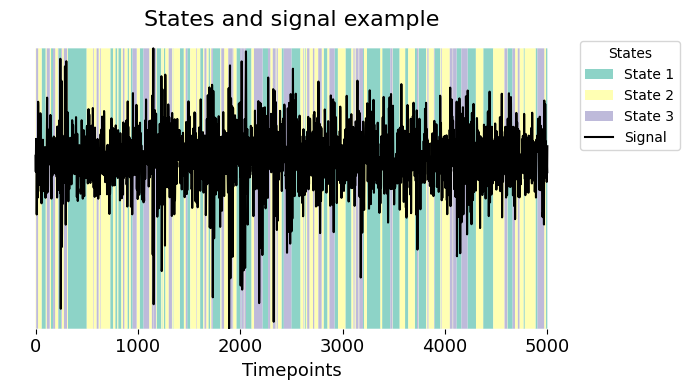

In [12]:
# Pad Gamma
T = auxiliary.get_T(idx_data)
options_mar ={'order':autoregressive_order}
paddedGamma = auxiliary.padGamma(stc_mar, T, options_mar)
paddedVP = auxiliary.padGamma(vpath_mar, T, options_mar)

# plot state time courses with signal
plotting_range = np.arange(5000,10000)
graphics.plot_vpath(paddedVP[plotting_range], signal=X_preproc[plotting_range,1].copy(), title="States and signal example")

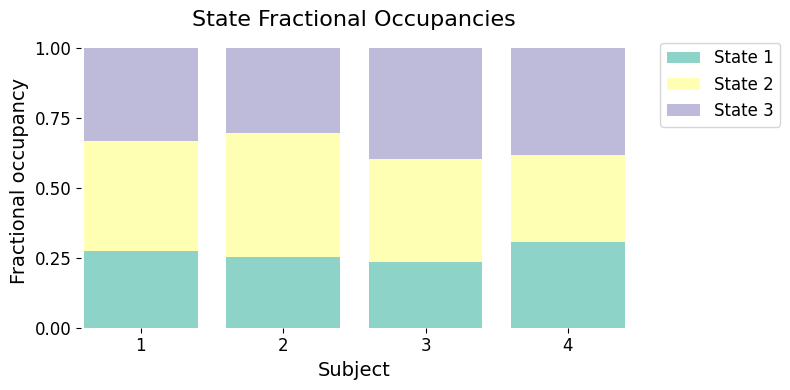

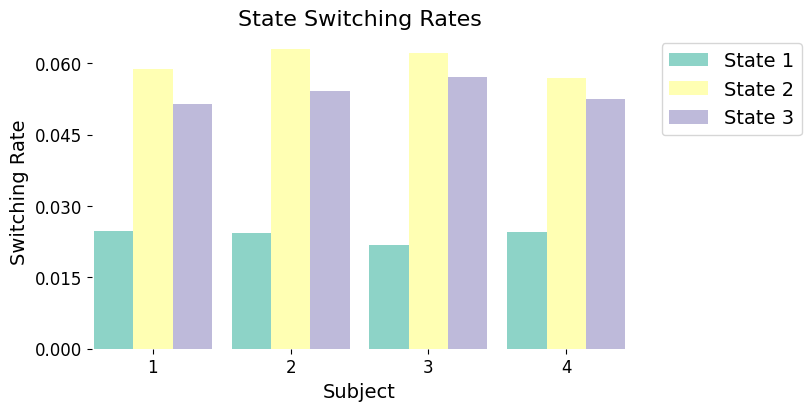

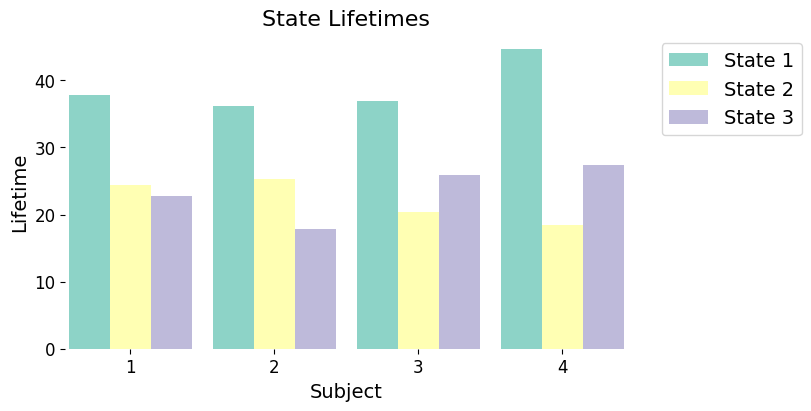

In [13]:
# inspect states metrics
FO = utils.get_FO(stc_mar, indices=idx_mar)
SR = utils.get_switching_rate(stc_mar, indices=idx_mar)
LTmean, LTmed, LTmax = utils.get_life_times(vpath_mar, indices=idx_mar)

# plot some relevant statistics
graphics.plot_FO(FO)
graphics.plot_switching_rates(SR)
graphics.plot_state_lifetimes(LTmean)

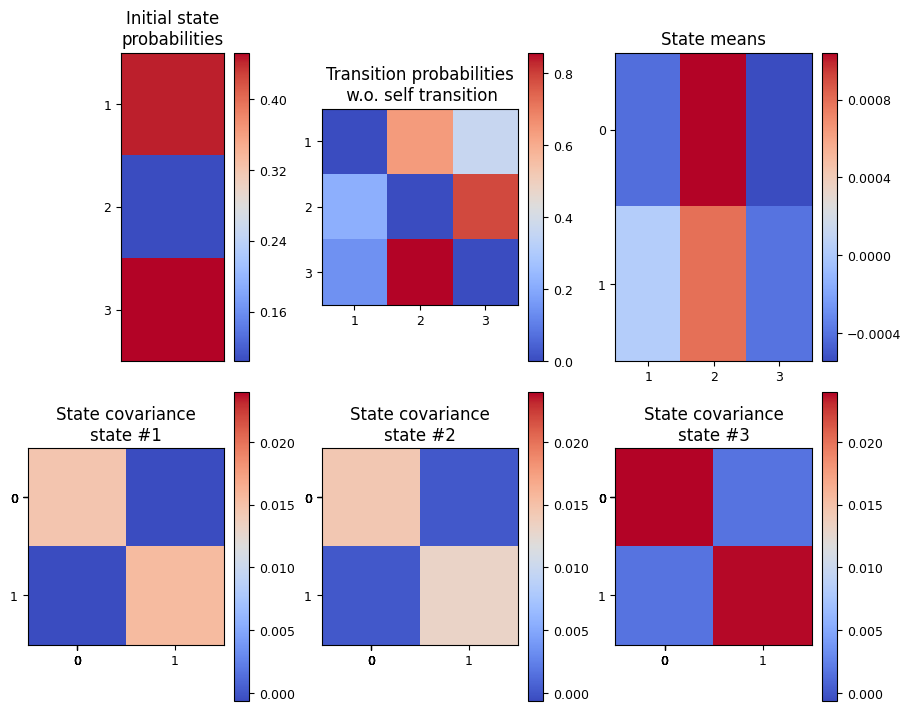

In [14]:
# plot the states covariance matrices
graphics.plot_state_prob_and_covariance(MAR_hmm.Pi,MAR_hmm.P, MAR_hmm.get_means(),MAR_hmm.get_covariance_matrices())

# Relate behavioural outcome to states probability

In [15]:
with open('./MEG_data/onset_tap_MAR.pkl', "rb") as f:
    onset = pickle.load(f)

C:\Users\pipo_\AppData\Local\Temp\ipykernel_22096\1259086677.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  onset = pickle.load(f)


In [24]:
len(onset)

4

In [16]:
# concatenate the onset
onset_concat = []

for i in range(len(onset)):
    onset_concat.extend(onset[i])

onset_concat = np.array(onset_concat)

# find the exact timing of the onset
onset_timing = np.where(onset_concat)[0]

In [32]:
onset_concat[712855]

np.uint8(1)

In [27]:
np.where(onset_concat)

(array([  3557,  11820,  11821,  12001,  22270,  30914,  42164,  54903,
         70193,  82369,  89860,  90001,  98276, 108376, 120962, 131391,
        147178, 157557, 167142, 172799, 187653, 198262, 211458, 218933,
        228038, 233870, 234001, 241153, 247183, 253759, 258792, 258793,
        265089, 272046, 279886, 287739, 297942, 297943, 305219, 310978,
        316983, 323703, 329541, 335364, 341692, 348095, 353955, 354001,
        359227, 366238, 372244, 377356, 383911, 389712, 396406, 401843,
        407906, 414121, 419631, 426169, 432208, 438322, 444686, 450756,
        453833, 459813, 465108, 471405, 477959, 478001, 483051, 489232,
        495860, 501926, 507604, 514182, 519418, 526127, 532221, 537415,
        560837, 573980, 583479, 593855, 604986, 615059, 623816, 624001,
        640630, 651673, 661696, 673109, 680306, 688810, 699238, 705875,
        712855, 715857, 719531, 729254, 734531, 740750, 746760, 753450,
        758381, 765195, 771120, 776987, 783021, 789030, 798196, 

In [37]:
onset_timing

array([  3557,  11820,  11821,  12001,  22270,  30914,  42164,  54903,
        70193,  82369,  89860,  90001,  98276, 108376, 120962, 131391,
       147178, 157557, 167142, 172799, 187653, 198262, 211458, 218933,
       228038, 233870, 234001, 241153, 247183, 253759, 258792, 258793,
       265089, 272046, 279886, 287739, 297942, 297943, 305219, 310978,
       316983, 323703, 329541, 335364, 341692, 348095, 353955, 354001,
       359227, 366238, 372244, 377356, 383911, 389712, 396406, 401843,
       407906, 414121, 419631, 426169, 432208, 438322, 444686, 450756,
       453833, 459813, 465108, 471405, 477959, 478001, 483051, 489232,
       495860, 501926, 507604, 514182, 519418, 526127, 532221, 537415,
       560837, 573980, 583479, 593855, 604986, 615059, 623816, 624001,
       640630, 651673, 661696, 673109, 680306, 688810, 699238, 705875,
       712855, 715857, 719531, 729254, 734531, 740750, 746760, 753450,
       758381, 765195, 771120, 776987, 783021, 789030, 798196, 804591,
      

In [33]:
# now select a window around the timings - let's say 4 seconds, from -2 to +2 after the tapping

state_around_tap = []
for i in onset_timing:
    state_around_tap.append(paddedGamma[i-500:i+501,:])

state_around_tap = np.array(state_around_tap)

In [35]:
state_around_tap.shape

(140, 1001, 3)

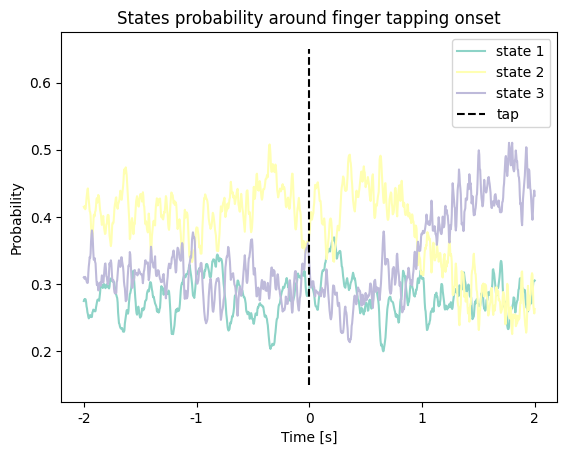

In [ ]:
# plot average state probability around finger tapping
K=3 # number of states
cmap = plt.get_cmap('Set3')
component_colors = [cmap(i) for i in range(K)]
plt.figure()
for k in range(K):
    plt.plot(np.arange(-500,501),np.mean(state_around_tap[:,:,k],0), color=component_colors[k], label='state %d'%(k+1))
plt.xticks(np.arange(-500,501,Fs), np.arange(-2,3))
plt.vlines(x=0, ymin=0.15,ymax=0.65,linestyle='--', color='k', label='tap')
#plt.yticks([0,0.5,1])
plt.legend()
plt.xlabel('Time [s]')
plt.ylabel('Probability')
plt.title('States probability around finger tapping onset')
plt.show()

**Get states spectral properties**

In [19]:
spectral_measures = spectral.multitaper_spectral_analysis(X_preproc, idx_data, Fs=250, Gamma=paddedGamma, options={'fpass':[0,50]})

c:\Users\pipo_\miniconda3\envs\glhmm\lib\site-packages\glhmm\spectral.py:303: ComplexWarning: Casting complex values to real discards the imaginary part
  psdc[j,:,:,:,k] = psdc_sk.transpose(2,0,1)


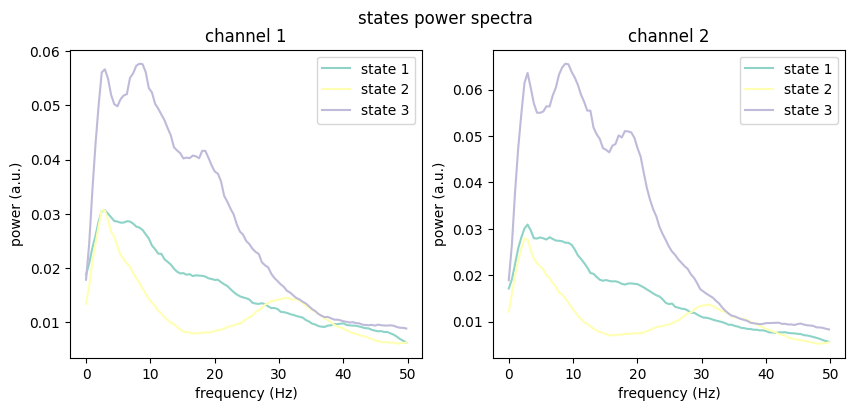

In [20]:
# plot state power spectra per channel
select_subject = 2
cmap = plt.get_cmap('Set3')
component_colors = [cmap(i) for i in range(K)]
f = spectral_measures['f']
psd = spectral_measures['p']
fig, axs= plt.subplots(ncols=2, figsize=(10,4))
for i in range(2):
    for k in range(K):
        axs[i].plot(f,psd[select_subject,:,i,k], color=component_colors[k],label='state %d'%(k+1))
        axs[i].set_xlabel('frequency (Hz)')
        axs[i].set_ylabel('power (a.u.)')
        axs[i].legend()
        axs[i].set_title("channel %d"%(i+1))
fig.suptitle('states power spectra')
plt.show()

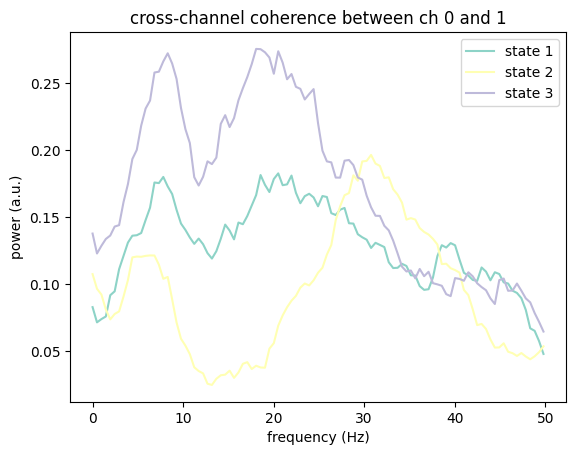

In [21]:
# for a specific session, plot the state coherence between two channels
K=3
coh = spectral_measures['coh']
chann_1 = 0
chann_2 = 1
fig = plt.figure()
for k in range(K):
    plt.plot(f,coh[select_subject,:,chann_1,chann_2,k],color=component_colors[k], label='state %d'%(k+1))
    plt.xlabel('frequency (Hz)')
    plt.ylabel('power (a.u.)')
    plt.legend()
    plt.title("cross-channel coherence between ch %d and %d"%(chann_1,chann_2))
plt.show()